# Name: Nadeen Tarek Mohammed
# Cycle: C12

# Part 1: Data Loading & Initial Inspection
1. Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).
2. Load healthcare-dataset-stroke-data.csv into DataFrame df
3. Display first 5 rows using df.head()
4. Use df.info() to check data types, non-null values, memory usage
5. Use df.describe() for statistical summaries


In [ ]:
# 1.Import important libraries (pandas, numpy, matplotlib, seaborn, sklearn).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

In [ ]:
# 2.Load healthcare-dataset-stroke-data.csv into DataFrame df
# 3.Display first 5 rows using df.head()
df=pd.read_csv('healthcare-dataset-stroke-data.csv')
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
# 4.Use df.info() to check data types, non-null values, memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
# 5.Use df.describe() for statistical summaries
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


# Part 2: Exploratory Data Analysis & Visualization
1. Create countplot for stroke column (class distribution)
2. Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots
3. Drop 'Other' gender record (only 1 exists)
4. Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots
5. Create correlation heatmap using selected numerical features and stroke

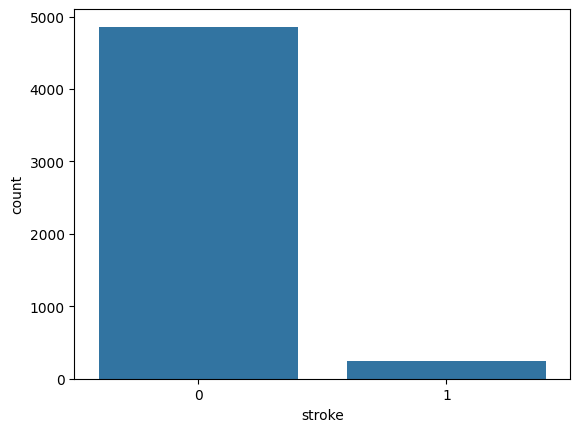

In [ ]:
# 1.Create countplot for stroke column (class distribution)
sns.countplot(x="stroke",data=df);

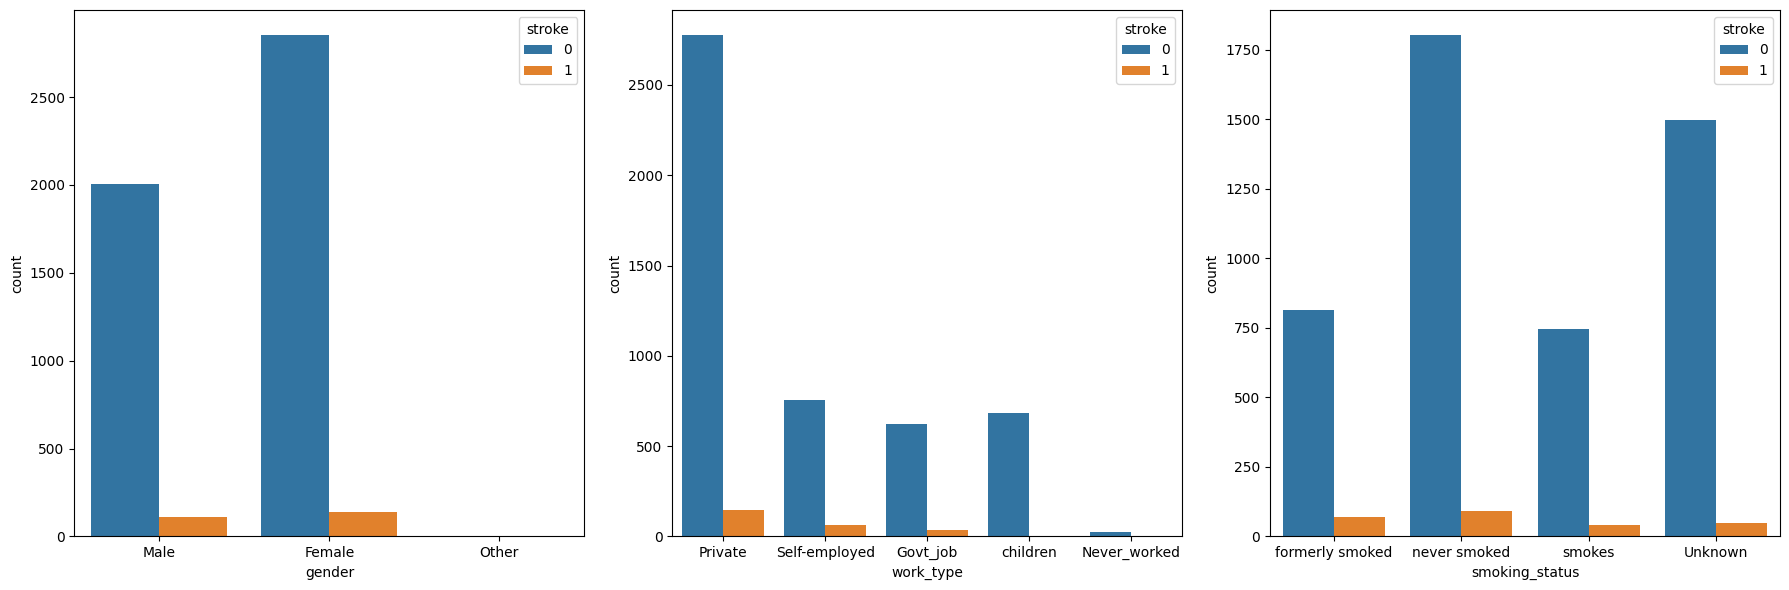

In [ ]:
# 2.Create countplots with hue='stroke' for gender, work_type, smoking_status using subplots
fig,axes=plt.subplots(1,3,figsize=(18,6))
sns.countplot(x='gender',hue='stroke',data=df,ax=axes[0]);
sns.countplot(x='work_type',hue='stroke',data=df,ax=axes[1]);
sns.countplot(x='smoking_status',hue='stroke',data=df,ax=axes[2]);
plt.tight_layout()



In [ ]:
# 3.Drop 'Other' gender record (only 1 exists)
df=df[df['gender']!='Other']

In [ ]:
df.gender.value_counts()

,count
gender,
Female,2994
Male,2115


<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

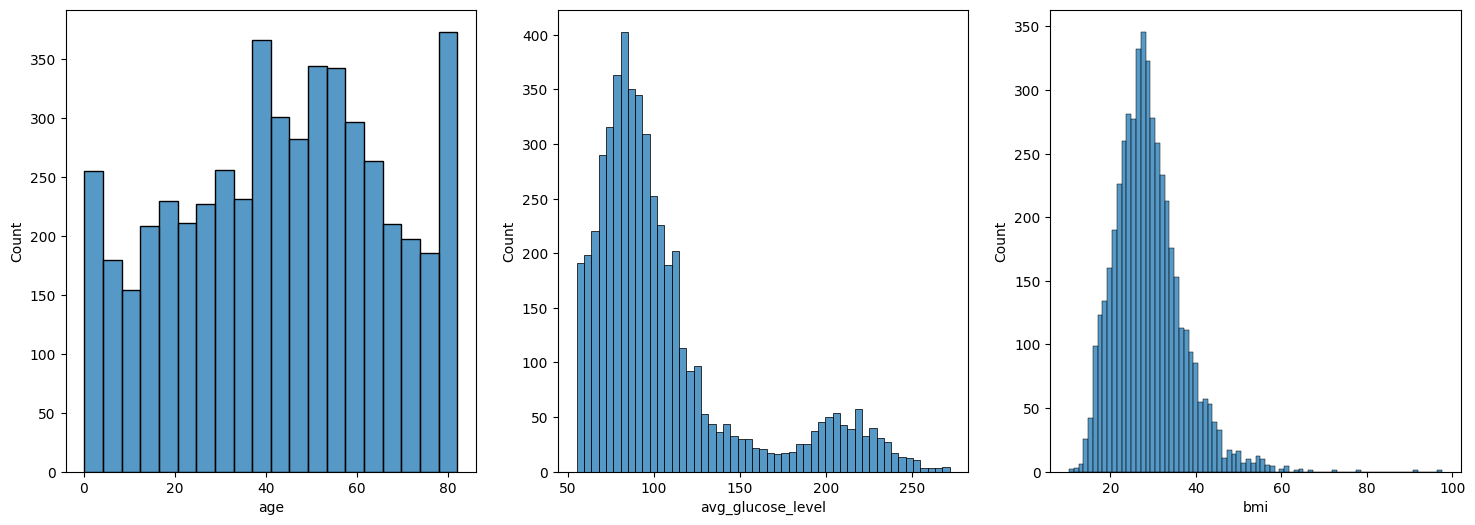

In [ ]:
# 4.Create histograms/KDE plots for age, avg_glucose_level, bmi using subplots
fig,axes=plt.subplots(1,3,figsize=(18,6))
sns.histplot(x="age",data=df,ax=axes[0]);
sns.histplot(x="avg_glucose_level",data=df,ax=axes[1]);
sns.histplot(x="bmi",data=df,ax=axes[2]);
plt.tight_layout

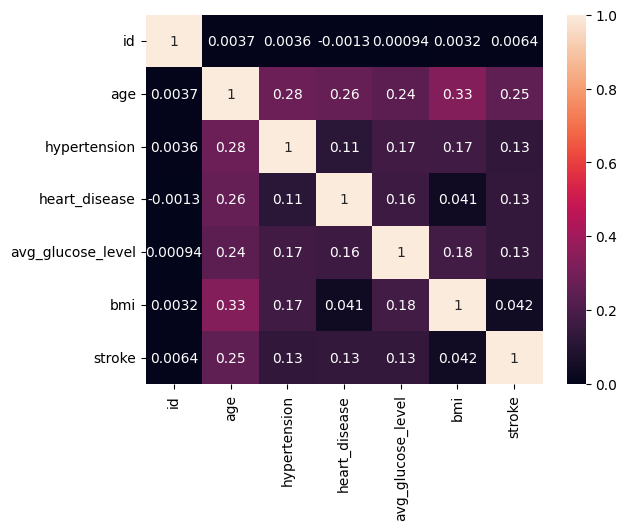

In [ ]:
# 5.Create correlation heatmap using selected numerical features and stroke
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True);

# Part 3: Data Preprocessing (Cleaning)
1. Check for missing values using df.isnull().sum()
2. Fill bmi missing values using mean or median
3. Verify no missing values remain
4. Check for duplicates and remove them if any exist
5. Drop id column (no predictive power)
6. Create boxplot for avg_glucose_level to detect outliers and remove if needed


In [ ]:
# 1.Check for missing values using df.isnull().sum()
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [ ]:
# 2.Fill bmi missing values using mean or median
df["bmi"]=df["bmi"].fillna(df["bmi"].mean())

In [ ]:
# 3.Verify no missing values remain
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


In [ ]:
# 4.Check for duplicates and remove them if any exist
df.duplicated().sum()

np.int64(0)

In [ ]:
# 5.Drop id column (no predictive power)
df.drop(columns="id",inplace=True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.60000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.89456,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.50000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.40000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.00000,never smoked,1


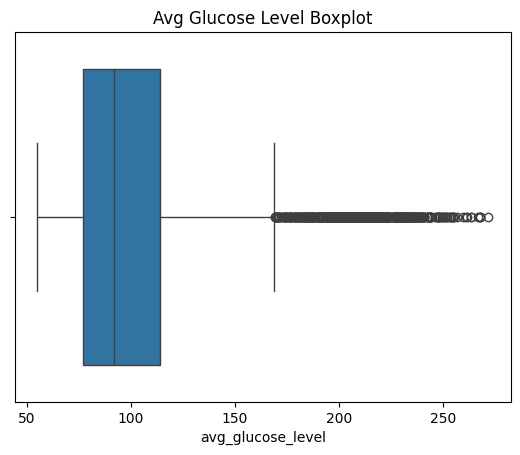

In [ ]:
# 6.Create boxplot for avg_glucose_level to detect outliers and remove if needed
sns.boxplot(x=df["avg_glucose_level"]);
plt.title("Avg Glucose Level Boxplot");


# Deleting Outliers (Optionally)

In [ ]:
# we can delete outliers if needed but in this case it is better to
# work on data based on it as it is medical data and these outliers could be real issues.

# Part 4: Feature Transformation
1. Encode categorical variables: gender, work_type, smoking_status, ever_married,
Residence_type
2. Reset DataFrame index
3. Apply one-hot encoding using pd.get_dummies() or OneHotEncoder

In [ ]:
# 1.Encode categorical variables: gender, work_type, smoking_status, ever_married, Residence_type
df.select_dtypes(include="object").columns

Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')

In [ ]:
for column in df.select_dtypes(include="object").columns:
  print(column,">>",df[column].unique())



gender >> ['Male' 'Female']
ever_married >> ['Yes' 'No']
work_type >> ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type >> ['Urban' 'Rural']
smoking_status >> ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


In [ ]:
# 2.Reset DataFrame index
df.reset_index(drop=True,inplace=True)
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.60000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.89456,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.50000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.40000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.00000,never smoked,1


In [ ]:
# 3.Apply one-hot encoding using pd.get_dummies() or OneHotEncoder
df=pd.get_dummies(df,columns=["gender","work_type","smoking_status","ever_married","Residence_type"],dtype=int)
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,...,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
0,67.0,0,1,228.69,36.60000,1,0,1,0,0,...,0,0,0,1,0,0,0,1,0,1
1,61.0,0,0,202.21,28.89456,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0
2,80.0,0,1,105.92,32.50000,1,0,1,0,0,...,0,0,0,0,1,0,0,1,1,0
3,49.0,0,0,171.23,34.40000,1,1,0,0,0,...,0,0,0,0,0,1,0,1,0,1
4,79.0,1,0,174.12,24.00000,1,1,0,0,0,...,1,0,0,0,1,0,0,1,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5109 entries, 0 to 5108
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             5109 non-null   float64
 1   hypertension                    5109 non-null   int64  
 2   heart_disease                   5109 non-null   int64  
 3   avg_glucose_level               5109 non-null   float64
 4   bmi                             5109 non-null   float64
 5   stroke                          5109 non-null   int64  
 6   gender_Female                   5109 non-null   int64  
 7   gender_Male                     5109 non-null   int64  
 8   work_type_Govt_job              5109 non-null   int64  
 9   work_type_Never_worked          5109 non-null   int64  
 10  work_type_Private               5109 non-null   int64  
 11  work_type_Self-employed         5109 non-null   int64  
 12  work_type_children              51

# Part 5: Data Splitting
1. Separate features X and target y
2. Use train_test_split() with 80/20 ratio and random_state=42
3. Verify shapes of X_train, X_test, y_train, y_test

In [ ]:
# 1.Separate features X and target y
x=df.drop(columns="stroke")
y=df["stroke"]

In [ ]:
# 2.Use train_test_split() with 80/20 ratio and random_state=42
X_train,X_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

# Part 6: Feature Scaling
1. Import StandardScaler or MinMaxScaler
2. Scale numerical features: age, avg_glucose_level, bmi
3. Fit scaler on training data only, then transform both train and test sets

In [ ]:
# 1.Import StandardScaler or MinMaxScaler
from sklearn.preprocessing import StandardScaler,MinMaxScaler


In [ ]:
# 2.Scale numerical features: age, avg_glucose_level, bmi
numerical_features=["age","avg_glucose_level","bmi"]
scaler=StandardScaler()




In [ ]:
# 3.Fit scaler on training data only, then transform both train and test sets
X_train[numerical_features]=scaler.fit_transform(X_train[numerical_features])
X_test[numerical_features]=scaler.transform(X_test[numerical_features])

In [ ]:
X_train[numerical_features].describe()

,age,avg_glucose_level,bmi
count,4.087000e+03,4.087000e+03,4.087000e+03
mean,2.781670e-17,1.747236e-16,1.069204e-16
std,1.000122e+00,1.000122e+00,1.000122e+00
min,-1.901125e+00,-1.123641e+00,-2.400912e+00
25%,-7.992014e-01,-6.402855e-01,-6.591844e-01
50%,4.094884e-02,-3.180855e-01,-6.570665e-02
75%,7.926622e-01,1.753967e-01,5.019677e-01
max,1.721249e+00,3.645403e+00,8.862262e+00


# Part 7: Handling Class Imbalance
1. Check distribution of stroke
2. Apply oversampling/undersampling or SMOTE
3. Verify balanced distribution

stroke
0    3900
1     187
Name: count, dtype: int64



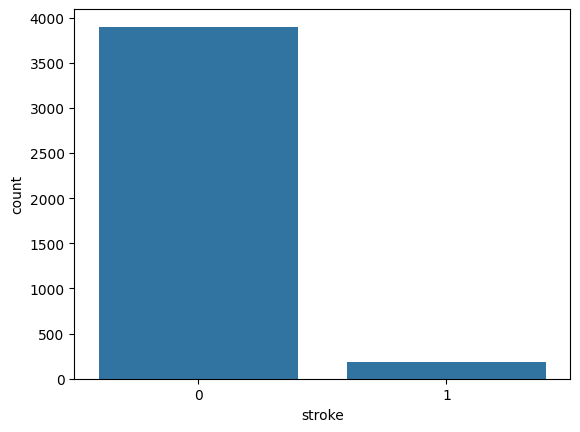

In [ ]:
# 1.Check distribution of stroke
print(y_train.value_counts())
print()
sns.countplot(x=y_train);


In [ ]:
# 2.Apply oversampling/undersampling or SMOTE
from imblearn.over_sampling import SMOTE
smote=SMOTE()
X_train_re, y_train_re=smote.fit_resample(X_train,y_train)


stroke
0    3900
1    3900
Name: count, dtype: int64



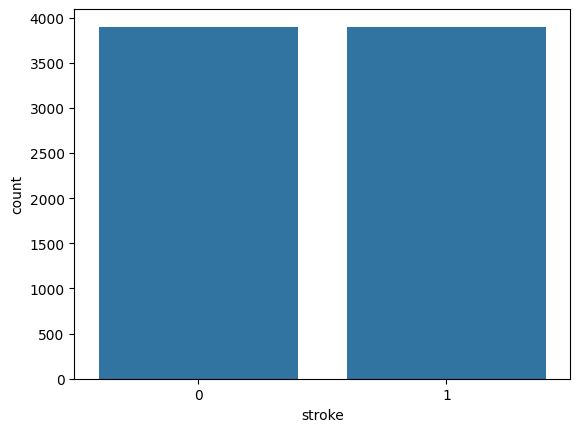

In [ ]:
# 3.Verify balanced distribution
print(y_train_re.value_counts())
print()
sns.countplot(x=y_train_re);

# Conclusion
Write a high-risk stroke patient persona and summarize findings.

# High-Risk Patient Persona
Illustrative Example
Patient ID: P001

Age: 75 years



Feature	Patient Value
- Gender>>	Male
- Age>>	75
- Hypertension>>	Yes
- Heart Disease>>	Yes
- Average Glucose>>	Elevated
- BMI>>	Elevated
- Smoking Status>>	Formerly Smoked
- Stroke>>	Risk factors present


Potential Risk Factors
- Advanced age.
- Hypertension.
- Heart disease.
- Elevated glucose level.
Recommendation: Regular medical checkups and appropriate management of cardiovascular risk factors.